# Workshop 1: ภาพคืออะไร
**เป้าหมาย:** เปิดภาพ ดูว่าคอมพิวเตอร์เห็นภาพเป็นตัวเลขอย่างไร แยกชั้นสี RGB และ HSV แล้วลอง Threshold กับ Canny

วิธีใช้: คลิกที่ cell แล้วกด **Shift + Enter** เพื่อรันทีละ cell จากบนลงล่าง

In [10]:
import sys, os
sys.path.insert(0, os.path.abspath("../scripts"))   # ให้หาไฟล์ vision_camera.py เจอ

import cv2
import numpy as np
from vision_camera import show, grab_one, img_path, put_label, add_source_args, open_source, fit_to_screen, put_label
print("OpenCV", cv2.__version__, "พร้อมใช้งาน")

OpenCV 4.12.0 พร้อมใช้งาน


## 1. เปิดภาพ

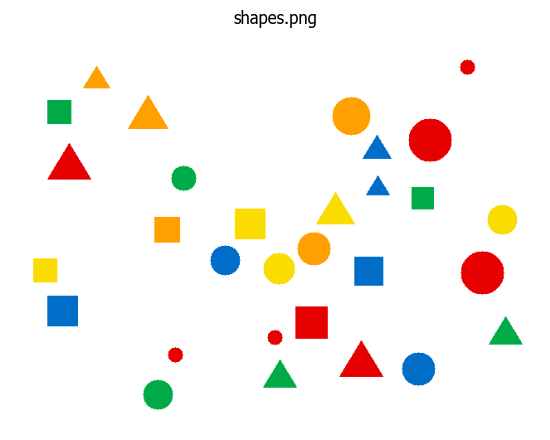

In [11]:
img = cv2.imread(img_path("shapes.png"))
show(img, titles=["shapes.png"])

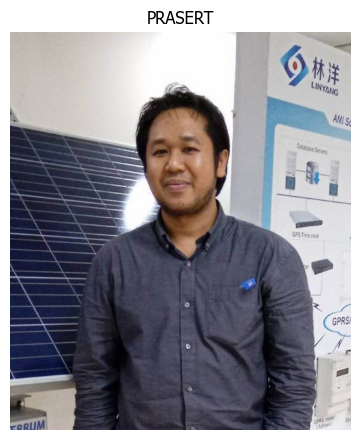

In [12]:
img = cv2.imread(img_path("fadlee.jpg"))
show(img, titles=["PRASERT"])

ขนาด: (480, 512, 3)


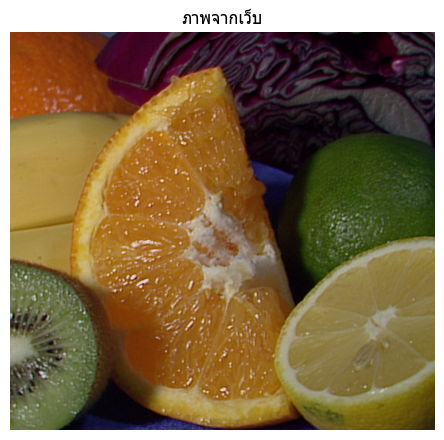

In [13]:
from vision_camera import imread_url

url = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg"
web_img = imread_url(url)
print("ขนาด:", web_img.shape)
show(web_img, titles=["ภาพจากเว็บ"])


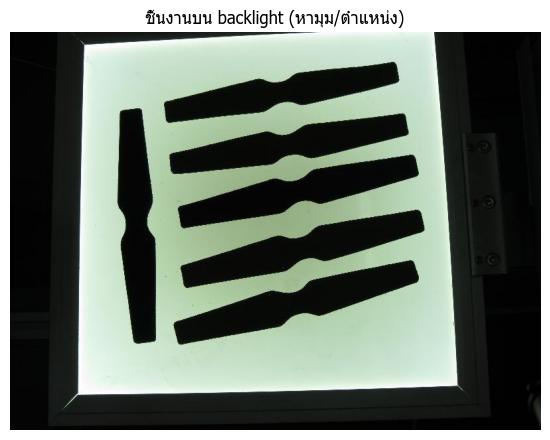

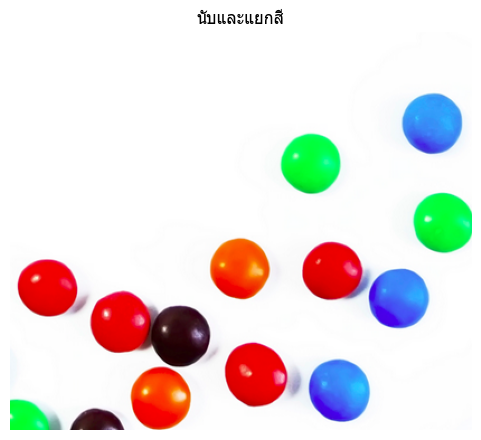

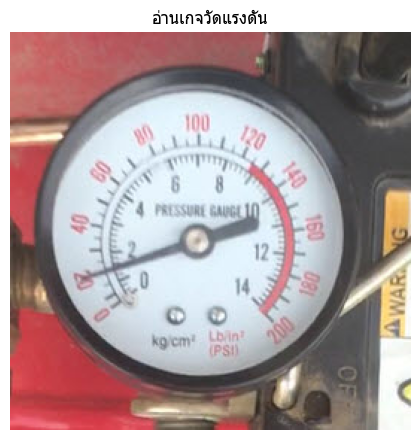

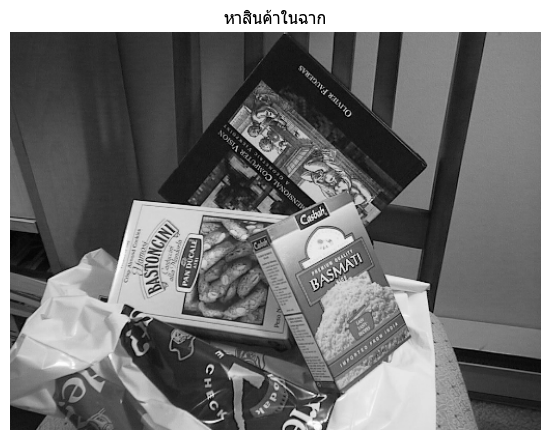

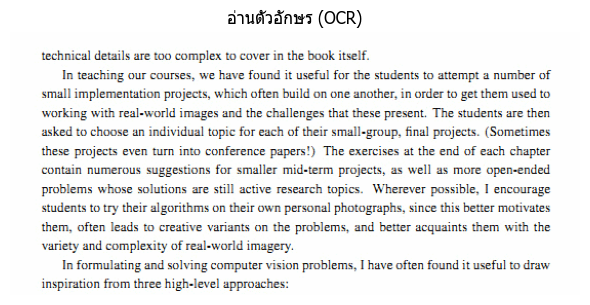

In [14]:
from vision_camera import imread_url

BASE = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
examples = {
    "ชิ้นงานบน backlight (หามุม/ตำแหน่ง)": "pca_test1.jpg",
    "นับและแยกสี":                        "smarties.png",
    "อ่านเกจวัดแรงดัน":                    "gauge-1.jpg",
    "หาสินค้าในฉาก":                       "box_in_scene.png",
    "อ่านตัวอักษร (OCR)":                  "imageTextN.png",
}

web = {}
for title, name in examples.items():
    web[name] = imread_url(BASE + name)
    show(web[name], titles=[title])


## 2. ภาพคือตัวเลข 3 มิติ
`img.shape` บอก (สูง, กว้าง, ชั้นสี)  ส่วน `img[แถว, คอลัมน์]` คือค่าสีของพิกเซล 1 จุด
**ระวัง:** OpenCV เรียงสีเป็น **B, G, R**

In [30]:
print("ขนาด (สูง, กว้าง, ชั้นสี):", img.shape)
print("ชนิดข้อมูล:", img.dtype, " (ค่า 0-255)")
print("พิกเซลมุมซ้ายบน [B G R]:", img[0, 0])
# print("พิกเซลในวงกลมแดง [B G R]:", img[270, 570])    #480, 512
print("พิกเซลในวงกลมแดง [B G R]:", img[int(480/2), int(521/2)])

ขนาด (สูง, กว้าง, ชั้นสี): (614, 525, 3)
ชนิดข้อมูล: uint8  (ค่า 0-255)
พิกเซลมุมซ้ายบน [B G R]: [172 180 187]
พิกเซลในวงกลมแดง [B G R]: [ 99  98 154]


## 3. ซูมจนเห็นพิกเซล
ตัดภาพเล็กๆ 16 × 16 พิกเซลที่ขอบวงกลมแดง แล้วขยายแบบไม่เกลี่ยสี (`INTER_NEAREST`) จะเห็นเป็นช่องสี่เหลี่ยม

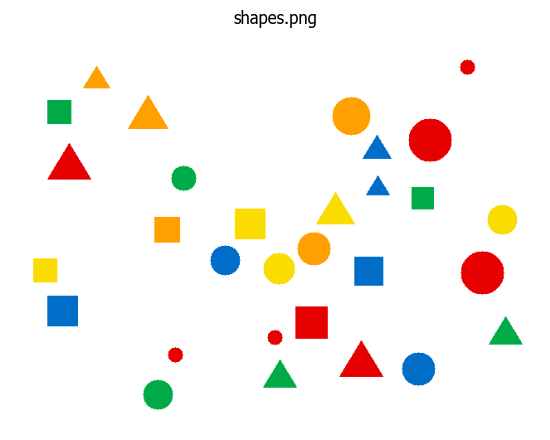

In [ ]:
img = cv2.imread(img_path("shapes.png"))
show(img, titles=["shapes.png"])


In [ ]:
print("ขนาด (สูง, กว้าง, ชั้นสี):", img.shape)

print("พิกเซลมุมซ้ายบน [B G R]:", img[, 300])

ขนาด (สูง, กว้าง, ชั้นสี): (480, 640, 3)
พิกเซลมุมซ้ายบน [B G R]: [255 255 255]


In [ ]:

'''
import cv2

# ฟังก์ชันดักจับการคลิกเมาส์
def click_event(event, x, y, flags, params):
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"พิกัดพิกเซลที่คลิก: X={x}, Y={y}")

# โหลดรูปภาพ
img = cv2.imread("shape.png")
cv2.imshow("shape.png", img)

# เรียกใช้ฟังก์ชันเมื่อมีการคลิกเมาส์บนรูป
cv2.setMouseCallback("shape.png", click_event)

cv2.waitKey(0)
cv2.destroyAllWindows()

'''

error: OpenCV(4.12.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:973: error: (-215:Assertion failed) size.width>0 && size.height>0 in function 'cv::imshow'


In [ ]:
# crop = img[262:278, 537:553]
big = cv2.resize(crop, (320, 320), interpolation=cv2.INTER_NEAREST)
show(img, big, titles=["ภาพเต็ม", "ซูม 16 x 16 พิกเซล"])

error: OpenCV(4.12.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'cv::resize'


## 4. ภาพเทา (Gray) = 1 ตัวเลขต่อพิกเซล
สูตร: **Gray = 0.299R + 0.587G + 0.114B**  แดง (230, 0, 0) จึงได้ประมาณ 0.299 × 230 ≈ 69

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("ขนาดภาพเทา:", gray.shape, " (ไม่มีชั้นสีแล้ว)")
print("ค่าเทาของวงกลมแดง:", gray[270, 570])
show(img, gray, titles=["ภาพสี", "ภาพเทา"])

## 5. แยกชั้นสี B, G, R
บริเวณที่สว่างในแต่ละชั้น = มีสีนั้นมาก

In [ ]:
b, g, r = cv2.split(img)
show(b, g, r, titles=["B น้ำเงิน", "G เขียว", "R แดง"], size=4)

## 6. HSV: บอกสีด้วย 3 คำถาม
**H** สีอะไร (0-179)  **S** สดแค่ไหน (0-255)  **V** สว่างแค่ไหน (0-255)

In [ ]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
print("วงกลมแดง [H S V]:", hsv[270, 570], " <- H = 0 คือสีแดง")
show(h, s, v, titles=["H สีอะไร", "S สดแค่ไหน", "V สว่างแค่ไหน"], size=4)

## 7. Threshold: แปลงเป็นภาพขาว-ดำ
เลื่อนแถบ **T** แล้วสังเกต: ถ้า T สูงเกินไป วัตถุบางชิ้นจะหายไป
(กลับสีภาพเทาก่อน เพื่อให้วัตถุสว่างบนพื้นมืด)

In [ ]:
from ipywidgets import interact

inv = 255 - gray
def try_threshold(T=100):
    _, bw = cv2.threshold(inv, T, 255, cv2.THRESH_BINARY)
    show(inv, bw, titles=["ภาพเทา (กลับสี)", f"Threshold T = {T}"])

interact(try_threshold, T=(0, 255, 5));

## 8. Canny: หาขอบวัตถุ
เลื่อนค่า low / high แล้วดูว่าเส้นขอบเปลี่ยนอย่างไร

In [ ]:
def try_canny(low=50, high=150):
    edges = cv2.Canny(gray, low, high)
    show(img, edges, titles=["ภาพต้นฉบับ", f"Canny ({low}, {high})"])

interact(try_canny, low=(0, 255, 5), high=(0, 255, 5));

## ลองเอง
1. เปลี่ยนตำแหน่งใน `img[270, 570]` เป็นจุดอื่น แล้วดูว่าได้สีอะไร
2. ถ่ายรูปด้วยมือถือ ใส่ไว้ในโฟลเดอร์ `images/` แล้วเปลี่ยนชื่อไฟล์ใน cell ข้อ 1